# Αναλυση Δεδομενων Αυτοκινητων και Προβλεψη Καταναλωσης Καυσιμου
Στο project αυτο αναλυουμε δεδομενα αυτοκινητων με τη χρηση Python. Εξεταζουμε πως χαρακτηριστικα οπως το βαρος, η ιπποδυναμη και ο κυβισμος σχετιζονται με την καταναλωση καυσιμου.
Στη συνεχεια χρησιμοποιουμε μοντελα παλινδρομησης για να προβλεψουμε την καταναλωση σε L/100km. Τελος, συγκρινουμε τα αποτελεσματα και αξιολογουμε την αποδοση των μοντελων. (project ακομα υπο κατασκευη)

In [1]:
# Εισαγωγη βιβλιοθηκης
import pandas as pd

# Ορισμος στηλων των δεδομενων
columns = [
    'mpg', 'cylinders', 'displacement',
    'horsepower', 'weight', 'acceleration',
    'model_year', 'origin', 'car_name'
]

# Αναγνωση αρχειου απο την python
df = pd.read_csv(
    'auto-mpg.data',
    sep=r'\s+',
    header=None,
    names=columns,
    na_values='?'
)

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


## 1. Data inseption
Χρήσιμες πληροφορίες για τα δεδομένα μας

In [2]:
print('Διαστάσεις δεδομένων:', df.shape)

print('\nΠληροφορίες δεδομένων:')
df.info()

print('\nΆθροισμα δεδομένων που λείπουν ανά στήλη:')
print(df.isnull().sum())

print('\nΒασικά στατιστικά αποτελέσματα:')
display(df.describe())

Διαστάσεις δεδομένων: (398, 9)

Πληροφορίες δεδομένων:
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(5), int64(3), str(1)
memory usage: 28.1 KB

Άθροισμα δεδομένων που λείπουν ανά στήλη:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

Βασικά στατιστικά αποτελέσματα:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


## 2. Καθαρισμος δεδομενων
Παρατηρησαμε προηγουμενως οτι λειπουν 6 δεδομενα στη στηλη horsepower οποτε θα τα αντικαταστησουμε με τον μεσο ορο της στηλης αυτης

In [3]:
df[df['horsepower'].isnull()]


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
32,25.0,4,98.0,NaN,2046.0,19.0,71,1,ford pinto
126,21.0,6,200.0,NaN,2875.0,17.0,74,1,ford maverick
330,40.9,4,85.0,NaN,1835.0,17.3,80,2,renault lecar deluxe
336,23.6,4,140.0,NaN,2905.0,14.3,80,1,ford mustang cobra
354,34.5,4,100.0,NaN,2320.0,15.8,81,2,renault 18i
374,23.0,4,151.0,NaN,3035.0,20.5,82,1,amc concord dl


In [4]:
#Εισαγουμε numpy
import numpy as np

In [5]:
# Μετατρεπουμε τη στηλη horsepower σε float και υπολογιζουμε στη στηλη αυτη (axis=0) τον μεσο ορο

avg_horsepower = df['horsepower'].astype('float').mean(axis=0)
print('average horsepower: ', avg_horsepower)

# Αντικατασταση Nan με avg_horsepower
df['horsepower'] = df['horsepower'].replace(np.nan, avg_horsepower)
print(df['horsepower'].isnull().sum())

average horsepower:  104.46938775510205
0


### Παρατηρηση
Για να δουλεψουμε καλυτερα με τα δεδομενα θα ηταν ευλογο να μετατρεψουμε το mpg(μιλια ανα γαλονι) σε L/100Km(Λιτρο ανα 100 χιλιομετρα) και το βαρος απο lbs σε kg

In [6]:
# Μετατροπη απο mpg σε L/100Km
df['mpg'] = 235.215 / df['mpg']

# Μετατροπη lbs σε kg
df['weight'] = df['weight'] / 2.2046

# Αλλαγη ονοματος στηλης mpg
df.rename(columns = {'mpg': 'L/100Km'}, inplace=True)

#Ελεγχος αποτελεσματων
df.head()

# Για οπτικους λογους θα καλουμε πλεον 
# df.head().round({'weight': 1})
# Διοτι θα χρησιμοποιησουμε το βαρος στη συνεχεια για προβλεψεις
# Και γι αυτο οι πραγματικες τιμες του βαρους παραμενουν χρησιμες

,L/100Km,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,13.067500,8,307.0,130.0,1589.403974,12.0,70,1,chevrolet chevelle malibu
1,15.681000,8,350.0,165.0,1675.133811,11.5,70,1,buick skylark 320
2,13.067500,8,318.0,150.0,1558.559376,11.0,70,1,plymouth satellite
3,14.700938,8,304.0,150.0,1557.198585,12.0,70,1,amc rebel sst
4,13.836176,8,302.0,140.0,1564.456137,10.5,70,1,ford torino


# 3. Διερευνητική Ανάλυση Δεδομένων
Εξετάζουμε τις σχέσεις μεταξύ των χαρακτηριστικών των οχημάτων και της απόδοσης καυσίμου (MPG).

In [7]:
# Συσχετισεις ολων
df.corr(numeric_only=True)

,L/100Km,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
L/100Km,1.000000,0.839278,0.866631,0.850880,0.885219,-0.455750,-0.557427,-0.530213
cylinders,0.839278,1.000000,0.950721,0.838939,0.896017,-0.505419,-0.348746,-0.562543
displacement,0.866631,0.950721,1.000000,0.893646,0.932824,-0.543684,-0.370164,-0.609409
horsepower,0.850880,0.838939,0.893646,1.000000,0.860574,-0.684259,-0.411651,-0.453669
weight,0.885219,0.896017,0.932824,0.860574,1.000000,-0.417457,-0.306564,-0.581024
acceleration,-0.455750,-0.505419,-0.543684,-0.684259,-0.417457,1.000000,0.288137,0.205873
model_year,-0.557427,-0.348746,-0.370164,-0.411651,-0.306564,0.288137,1.000000,0.180662
origin,-0.530213,-0.562543,-0.609409,-0.453669,-0.581024,0.205873,0.180662,1.000000


In [8]:
# Συσχετισεις μονο με L/100Km
df.corr(numeric_only=True)['L/100Km']

L/100Km         1.000000
cylinders       0.839278
displacement    0.866631
horsepower      0.850880
weight          0.885219
acceleration   -0.455750
model_year     -0.557427
origin         -0.530213
Name: L/100Km, dtype: float64

### Παρατηρησεις
Βλεπουμε οτι υπαρχει μεγαλη θετικη συσχετιση μεταξυ των τιμων mpg(αποδοση καυσιμου), cylinders(αριθμος κυλινδρων κινητηρα), displacement(Κυβικα κινητηρα), horsepower(ιπποδυναμη) και weight(βαρος)

## 4. Οπτικοποιηση δεδομενων

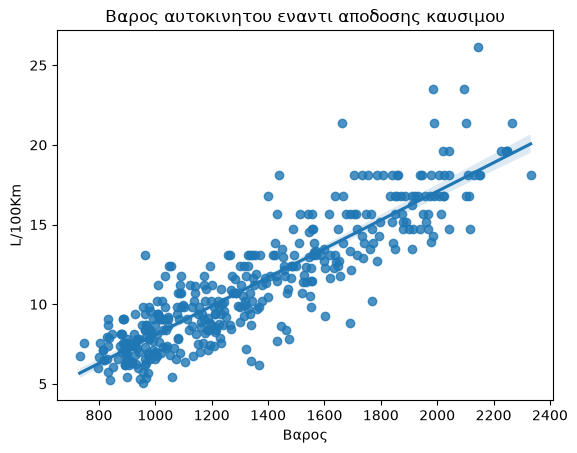

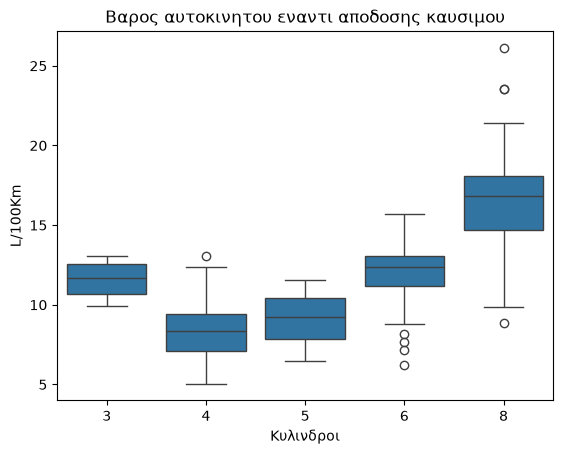

In [ ]:
# Εγκατασταση seaborn και matplotlib για γραφηματα
import seaborn as sns
import matplotlib.pyplot as plt

sns.regplot(x='weight', y='L/100Km', data=df)

plt.title('Βαρος αυτοκινητου εναντι καταναλωσης καυσιμου')
plt.xlabel('Βαρος')
plt.ylabel('L/100Km')
plt.show()

sns.boxplot(x='cylinders', y='L/100Km', data=df)

plt.title('Κατανάλωση καυσίμου ανά αριθμό κυλίνδρων')
plt.xlabel('Κυλινδροι')
plt.ylabel('L/100Km')
plt.show()

## Παρατηρησεις

### Σχεση βαρους και καταναλωσης καυσιμου
Παρατηρουμε οτι υπαρχει ισχυρη θετικη συσχετιση μεταξυ βαρους και καταναλωσης καυσιμου. Οσο αυξανεται το βαρος, τοσο αυξανεται και η καταναλωση. Η σχεση φαινεται σχεδον γραμμικη, με καποιες αποκλισεις.
### Σχεση κυλινδρων και καταναλωσης καυσιμου
Απο το Boxplot βλεπουμε οτι τα αυτοκινητα με περισσοτερους κυλινδρους εχουν γενικα μεγαλυτερη καταναλωση. Τα 8κυλινδρα εχουν υψηλοτερη διαμεση τιμη απο τα 4κυλινδρα. Επισης παρουσιαζουν μεγαλυτερη διασπορα στις τιμες τους.

# 5. Γραμμικη Παλινδρομηση

## Αρχικη γραμμικη παλινδρομηση με χρηση ολοκληρου του συνολου δεδομενων

In [10]:
# %pip install scikit-learn 
# Εισαγουμε την γραμμικη παλινδρομιση
from sklearn.linear_model import LinearRegression

lre = LinearRegression()
print(lre)

LinearRegression()


In [96]:
# Εκπαιδευση μοντελου
lre.fit(df[['weight']], df['L/100Km'])

# Προβλεψη 5 τιμων του μοντελου
Yhat=lre.predict(df[['weight']])
print('Πρωτες 5 προβλεψεις:', Yhat[0:5])

print('Συντελεστης παλινδρομησης:', lre.coef_)
print('Σταθερος ορος:', lre.intercept_)

Πρωτες 5 προβλεψεις: [13.38948786 14.16040405 13.11212119 13.09988442 13.16514717]
Συντελεστης παλινδρομησης: [0.00899239]
Σταθερος ορος: -0.9030536518793575


## 5.1 Γραμμικη παλινδρομηση στο 90% των δεδομενων και αξιολογηση των προβλεψεων στο υπολοιπο 10%

In [12]:
# Δεδομενα βαρους για τα αυτοκινητα
x_data = df[['weight']]

# Δεδομενα που θελουμε να προβλεψουμε
y_data = df['L/100Km']

In [13]:
# Εισαγωγη train_test_split
from sklearn.model_selection import train_test_split

# Διαχωρισμος δεδομενων σε train και test
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.1, random_state=1)

print('Αριθμος δειγματων test:', x_test.shape[0])
print('Αριθμος δειγματων train:', x_train.shape[0])

Αριθμος δειγματων test: 40
Αριθμος δειγματων train: 358


In [14]:
lre1 = LinearRegression()
lre1.fit(x_train, y_train)

# Προβλεψη 5 τιμων του μοντελου
Yhat1=lre1.predict(x_train)
print('Προβλεψεις:', Yhat1[0:5])

print('Συντελεστης παλινδρομησης:', lre1.coef_)
print('Σταθερος ορος:', lre1.intercept_)

Προβλεψεις: [ 7.76797284 10.34606319 14.32181462  8.03029046 10.12063399]
Συντελεστης παλινδρομησης: [0.00903602]
Σταθερος ορος: -0.9458905873272023


### Παρατηρηση
Οι συντελεστες και οι σταθεροι οροι στις δυο περιπτωσεις ειναι αρκετα κοντα μεταξυ τους οποτε αναμενουμε οι ευθειες "σχεδον" να ταυτιζονται

### Μπορουμε στη συνεχεια να δουμε με γραφημα ποσο καλα οι εκπεδευεσεις των μοντελων, με χρηση ολοκληρου του συνολου δεδομενων καθως και στην περιπτωση του διαχωρισμου σε training και test samples, ανταποκρινεται στα αγνωστα για το μοντελο test samples

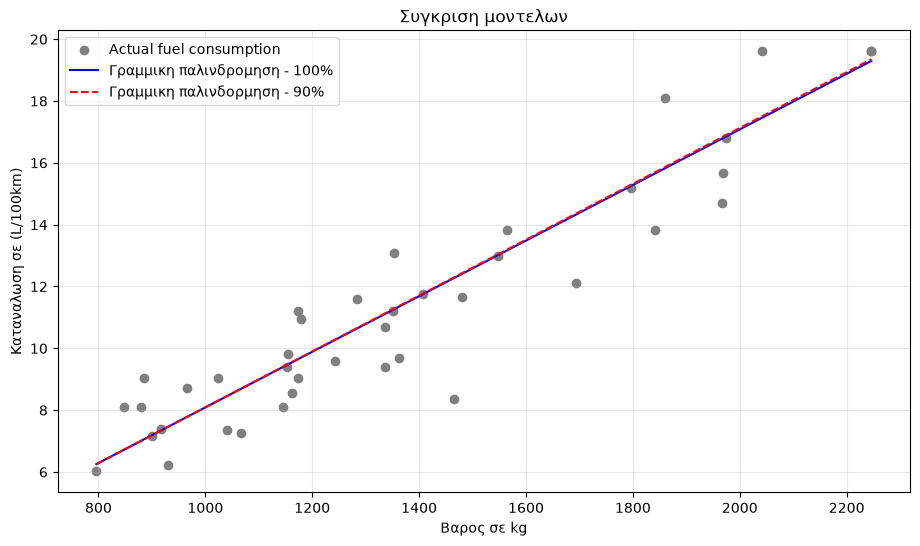

In [15]:
# Βαζουμε σε αυξουσα σειρα τις τιμες του βαρους στα δεδομενα
x_sorted = x_test.sort_values(by='weight')

# Διαστασεις γραφηματος
plt.figure(figsize=(11, 6))

# Πραγματικες τιμες καταναλωσης συνολου test
plt.scatter(x_test, y_test,
            color='gray',
            label='Actual fuel consumption')

# Μοντελο εκπαιδευμενο στο 100%
plt.plot(x_sorted, lre.predict(x_sorted),
         color='blue', 
         label='Γραμμικη παλινδρομηση - 100%')

# Μοντελο εκπαιδευμενο στο 90%
plt.plot(x_sorted, lre1.predict(x_sorted),
         color='red', linestyle='--',
         label='Γραμμικη παλινδορμηση - 90%')

# Στοιχεια γραφηματος
plt.xlabel('Βαρος σε kg')
plt.ylabel('Καταναλωση σε (L/100km)')
plt.title('Συγκριση μοντελων')

# Προσθετα
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Τι παρατηρουμε;
1. Οι δυο ευθειες σχεδον ταυτιζονται. Αυτο σημαίνει οτι η εκπαιδευση στο 90% των δεδομενων εδωσε πολυ παρομοιους συντελεστες με την εκπαιδευση στο 100%.

2. Υπαρχει σαφης θετικη σχεση μεταξυ βαρους και καταναλωσης. Οσο αυξανεται το βαρος, γενικα αυξανεται και η καταναλωση.

3. Υπαρχουν αποκλισεις απο τις πραγματικες τιμες. Ορισμενα αυτοκινητα βρισκονται αρκετα μακρια απο τις ευθειες, επομενως τα μοντελα δεν κανουν παντοτε ακριβεις προβλεψεις.

### Αξιολογηση μοντελων

In [16]:
# Εισαγουμε mse
from sklearn.metrics import mean_squared_error

# Υπολογισμος R^2 για καθε μοντελο

# Μοντελο γραμμικης παλινδρομισης - 90%
R2_lre1_train = lre1.score(x_train, y_train)
R2_lre1_test = lre1.score(x_test, y_test)

print('Γραμμικη παλινδρομιση - 90%')
print('Training R²:', R2_lre1_train)
print('Test R²:', R2_lre1_test)

# Μοντελο γραμμικης παλινδρομισης - 100%
R2_lre_train = lre.score(x_data, y_data)

print('\nΓραμμικη παλινδρομιση - 100%')
print('Training R²:', R2_lre_train)

# Υπολογισμος MSE για καθε μοντελο

# Μοντελο γραμμικης παλινδρομισης - 90%
lre1_weight_values_predict_train = lre1.predict(x_train)
lre1_weight_values_predict_test = lre1.predict(x_test)

lre1_mse_train = mean_squared_error(y_train, lre1_weight_values_predict_train)
lre1_mse_test = mean_squared_error(y_test, lre1_weight_values_predict_test)

print('\nΓραμμικη παλινδρομιση - 90%')
print('Training MSE:', lre1_mse_train)
print('Test MSE:', lre1_mse_test)

# Μοντελο γραμμικης παλινδρομισης - 100%

lre_weight_values_predict = lre.predict(x_data)
lre_mse = mean_squared_error(y_data, lre_weight_values_predict)

print('\nΓραμμικη παλινδρομιση - 100%')
print('MSE ολοκληρου συνολου:', lre_mse)



Γραμμικη παλινδρομιση - 90%
Training R²: 0.7748552712654996
Test R²: 0.870561404112411

Γραμμικη παλινδρομιση - 100%
Training R²: 0.7836118983544516

Γραμμικη παλινδρομιση - 90%
Training MSE: 3.4552479658092867
Test MSE: 1.7816329153164276

Γραμμικη παλινδρομιση - 100%
MSE ολοκληρου συνολου: 3.2865108179623963


Παρατηρουμε οτι το μοντελο αποδιδει καλυτερα στο Test Set, καθως εχει υψηλοτερο R² και μικροτερο MSE. Αυτο σημαινει οτι εξηγει περιπου το 87% της μεταβλητοτητας της καταναλωσης στα δεδομενα ελεγχου και παρουσιαζει μικροτερο μεσο τετραγωνικο σφαλμα. Ωστοσο, η καλυτερη αποδοση στο Test Set μπορει να οφειλεται στα συγκεκριμενα αυτοκινητα που επιλεχθηκαν τυχαια. Επισης, τα αποτελεσματα του μοντελου 100% δεν αποτελουν ανεξαρτητη αξιολογηση.
Στη συνεχεια θα εφαρμοσουμε Cross-Validation στο Training Set, ωστε να αξιολογησουμε το μοντελο σε διαφορετικες ομαδες δεδομενων και να εξετασουμε αν η αποδοση του παραμενει σταθερη, χωρις να χρησιμοποιησουμε ξανα το Test Set για την επιλογη μοντελου

In [17]:
# Εισαγουμε cross-validation
from sklearn.model_selection import cross_val_score

Rcross = cross_val_score(lre, x_train, y_train, cv=5)

print('R² για καθε fold:', Rcross)
print('Μεσο R²:', Rcross.mean())
print('Τυπικη αποκλιση R²:', Rcross.std())

R² για καθε fold: [0.77906806 0.78615157 0.77298011 0.81062764 0.71878316]
Μεσο R²: 0.7735221078655373
Τυπικη αποκλιση R²: 0.0302116788746844


Παρατηρουμε οτι η γραμμικη παλινδρομηση εχει σχετικα σταθερη αποδοση. Το μοντελο του 100% ειχε R² = 0.784, ενω το μοντελο του 90% ειχε Training R² = 0.775 και Test R² = 0.871. Με το 5 fold cross validation βρηκαμε μεσο 
R² = 0.774  με μικρες διαφορες μεταξυ των διαχωρισμων. Αυτο δειχνει οτι το βαρος ειναι χρησιμο για την προβλεψη της καταναλωσης. Ωστοσο δεν μπορουμε να συγκρινουμε αμεσα τα δυο μοντελα, καθως το μοντελο του 100% δεν ελεγθηκε σε αγνωστα δεδομενα. Στη συνεχεια θα δοκιμασουμε περισσοτερες μεταβλητες για να δουμε αν βελτιωνονται οι προβλεψεις.

# 6. Πολλαπλή γραμμική παλινδρόμηση

Ειναι λογικο να φτιαξουμε ενα μοντελο που θα λαμβανει υπ οψη ολες τις μεταβλητες που εχουν υψηλη συσχετιση με την καταναλωση καυσιμου L/100Km. Αυτες οι μεταβλητες οπως υπολογιστηκαν παραπανω ειναι: cylinders, displacement, horsepower, weight. Παραλληλα θα φτιαξουμε και ενα δευτερο μοντελο πολλαπλης γραμμικης παλινδρομησης με περισσοτερες μεταβλητες για να εξετασουμε ποιο και αν εχει καλυτερη αποδοση
Οριζουμε δυο περιπτωσεις που θα εξετασουμε
1. Περιπτωση οπου χρησιμοποιουμε cylinders, displacement, horsepower, weight για να εκπαιδευσουμε το μοντελο 
2. Περιπτωση οπου χρησιμοποιουμε καθε αριθμητικη τιμη απο τα δεδομενα μας εκτος της L/100Km

In [88]:
# Κατασκευη μοντελου με cylinders, displacement, horsepower, weight

# Εκπαιδευση
multi_lre = LinearRegression()
x_train_multi_lre, x_test_multi_lre, y_train_multi_lre, y_test_multi_lre = train_test_split(df[['cylinders', 'displacement', 'horsepower', 'weight']], df['L/100Km'], test_size=0.1, random_state=1)
multi_lre.fit(x_train_multi_lre, y_train_multi_lre)

# Cross_Validation
Rcross_multi_lre = cross_val_score(multi_lre, x_train_multi_lre, y_train_multi_lre, cv=5)

# Υπολογισμος R^2, MSE
r2_multi_lre_train = multi_lre.score(x_train_multi_lre, y_train_multi_lre)
r2_multi_lre_test = multi_lre.score(x_test_multi_lre, y_test_multi_lre)

# Training MSE
x_train_multi_lre_predict = multi_lre.predict(x_train_multi_lre)
mse_train_multi_lre = mean_squared_error(y_train_multi_lre, x_train_multi_lre_predict)

# Test MSE
x_test_multi_lre_predict = multi_lre.predict(x_test_multi_lre)
mse_test_multi_lre = mean_squared_error(y_test_multi_lre, x_test_multi_lre_predict)


# Εκτυπωση
print('R^2 πολλαπλης γραμμικης παλινδρομισης train', r2_multi_lre_train)
print('R^2 πολλαπλης γραμμικης παλινδρομισης test', r2_multi_lre_test)
print('MSE πολλαπλης γραμμικης παλινδρομισης train', mse_train_multi_lre)
print('MSE πολλαπλης γραμμικης παλινδρομισης test', mse_test_multi_lre)
print('\nCross_validation:')
print('R² για καθε fold:', Rcross_multi_lre)
print('Μεσο R²:', Rcross_multi_lre.mean())
print('Τυπικη αποκλιση R²:', Rcross_multi_lre.std())

R^2 πολλαπλης γραμμικης παλινδρομισης train 0.810209006829378
R^2 πολλαπλης γραμμικης παλινδρομισης test 0.8823578325542447
MSE πολλαπλης γραμμικης παλινδρομισης train 2.912681752611813
MSE πολλαπλης γραμμικης παλινδρομισης test 1.6192632214007283

Cross_validation:
R² για καθε fold: [0.83449912 0.80327373 0.78908352 0.79145921 0.77214423]
Μεσο R²: 0.798091962034955
Τυπικη αποκλιση R²: 0.02074011614208266


Σχεδον copy-paste κινουμαστε για ολες τις υπολοιπες μεταβλητες

In [89]:
# Κατασκευη μοντελου με ολες τις αριθμητικες στηλες

# Εκπαιδευση
multi_x_data = df.select_dtypes(include='number').drop('L/100Km', axis=1)
multi_x_data = pd.get_dummies(multi_x_data, columns=['origin'], drop_first=True, dtype=int)
multi_y_data = df['L/100Km']
multi1_lre1 = LinearRegression()
x_train_multi1_lre, x_test_multi1_lre, y_train_multi1_lre, y_test_multi1_lre = train_test_split(multi_x_data, multi_y_data, test_size=0.1, random_state=1)
multi1_lre1.fit(x_train_multi1_lre, y_train_multi1_lre)

# Cross_Validation
Rcross_multi1_lre = cross_val_score(multi1_lre, x_train_multi1_lre, y_train_multi1_lre, cv=5)

# Υπολογισμος R^2, MSE
r2_multi1_lre_train = multi1_lre.score(x_train_multi1_lre, y_train_multi1_lre)
r2_multi1_lre_test = multi1_lre.score(x_test_multi1_lre, y_test_multi1_lre)

# Training MSE
x_train_multi1_lre_predict = multi1_lre.predict(x_train_multi1_lre)
mse_train_multi1_lre = mean_squared_error(y_train_multi1_lre, x_train_multi1_lre_predict)

# Test MSE
x_test_multi1_lre_predict = multi1_lre.predict(x_test_multi1_lre)
mse_test_multi1_lre = mean_squared_error(y_test_multi1_lre, x_test_multi1_lre_predict)


# Εκτυπωση
print('R^2 πολλαπλης γραμμικης παλινδρομισης train', r2_multi1_lre_train)
print('R^2 πολλαπλης γραμμικης παλινδρομισης test', r2_multi1_lre_test)
print('MSE πολλαπλης γραμμικης παλινδρομισης train', mse_train_multi1_lre)
print('MSE πολλαπλης γραμμικης παλινδρομισης test', mse_test_multi1_lre)
print('\nCross_validation:')
print('R² για καθε fold:', Rcross_multi1_lre)
print('Μεσο R²:', Rcross_multi1_lre.mean())
print('Τυπικη αποκλιση R²:', Rcross_multi1_lre.std())

R^2 πολλαπλης γραμμικης παλινδρομισης train 0.8831129100815017
R^2 πολλαπλης γραμμικης παλινδρομισης test 0.9229219123288425
MSE πολλαπλης γραμμικης παλινδρομισης train 1.793841152490505
MSE πολλαπλης γραμμικης παλινδρομισης test 1.0609266664468413

Cross_validation:
R² για καθε fold: [0.88928434 0.87246942 0.87547683 0.88877263 0.84749235]
Μεσο R²: 0.8746991147239556
Τυπικη αποκλιση R²: 0.015209055418977822


Παρατηρουμε οτι η χρηση περισσοτερων χαρακτηριστικων βελτιωσε την αποδοση της γραμμικης παλινδρομησης. Το μοντελο με 4 μεταβλητες ειχε μεσο Cross-Validation R² = 0.798, ενω το μοντελο με ολα τα χαρακτηριστικα εφτασε στο 0.875. Η μικρη τυπικη αποκλιση (0.015) δειχνει σχετικα σταθερη αποδοση. Συνεπως, η προσθηκη περισσοτερων χαρακτηριστικων φαινεται να βελτιωνει τις προβλεψεις της καταναλωσης.

Θα ελεγξουμε τωρα για ποιο βαθμο αποδιδει καλυτερα το μοντελο σε καθε περιπτωση (1η, 2η)

1η περιπτωση

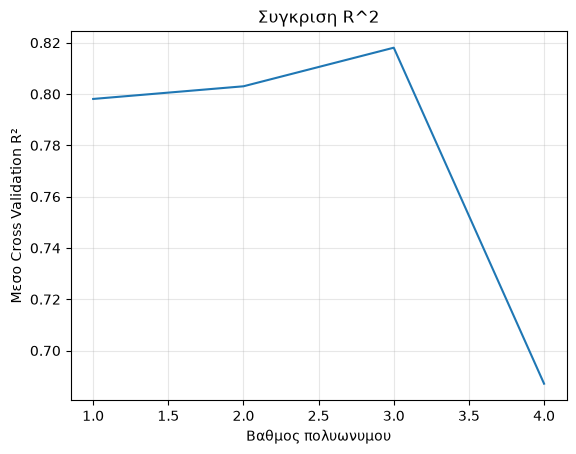

In [90]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

Rsqu_cv = []

order = [1, 2, 3, 4]

for n in order:

    pr = Pipeline([
        ('poly', PolynomialFeatures(degree=n, include_bias=False)),
        ('linear', LinearRegression())
        ])

    scores = cross_val_score(pr, x_train_multi_lre, y_train_multi_lre, cv=5,)

    Rsqu_cv.append(scores.mean())
    
plt.plot(order, Rsqu_cv)
plt.xlabel('Βαθμος πολυωνυμου')
plt.ylabel('Μεσο Cross Validation R²')
plt.title('Συγκριση R^2')
plt.grid(alpha=0.3)
plt.show()

2η περιπτωση

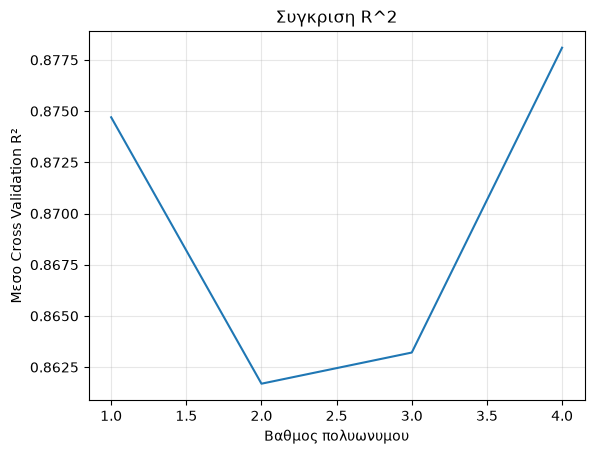

In [91]:
Rsqu_cv = []
order = [1, 2, 3, 4]

for n in order:
    pr = Pipeline([
        ('poly', PolynomialFeatures(degree=n, include_bias=False)),
        ('linear', LinearRegression())
    ])

    scores = cross_val_score(pr, x_train_multi1_lre, y_train_multi1_lre, cv=5)
    Rsqu_cv.append(scores.mean())

plt.plot(order, Rsqu_cv)
plt.xlabel('Βαθμος πολυωνυμου')
plt.ylabel('Μεσο Cross Validation R²')
plt.title('Συγκριση R^2')
plt.grid(alpha=0.3)
plt.show()

Παρατηρουμε οτι η πολυωνυμικη παλινδρομηση δεν προσφερει σημαντικη βελτιωση σε σχεση με την πολλαπλη γραμμικη παλινδρομηση. Ο 4ος βαθμος παρουσιασε το υψηλοτερο μεσο R² (0.878), αλλα η διαφορα απο το αρχικο μοντελο (0.875) ειναι πολυ μικρη. Παραλληλα, ο αριθμος των χαρακτηριστικων αυξανεται σημαντικα, φτανοντας τα 494 στον 4ο βαθμο. Επομενως, με βαση τα αποτελεσματα, προτιμαμε προς το παρον το απλουστερο μοντελο, καθως η αυξημενη πολυπλοκοτητα δεν προσφερει ουσιαστικη βελτιωση.

Συνεχιζουμε με ridge regression. Αρχικα εφαρμοζουμε ελεγχο για να δουμε οπως και πριν αν τελικα αξιζει να εκπαιδευσουμε το μοντελο
Αρχικα εξεταζουμε cylinders, displacement, horsepower, weight και πως αυτα επηρεαζουν το L/100Km

Βαθμός 1: best alpha = 13.738237958832638,
CV R² = 0.8007979249167896
Βαθμός 2: best alpha = 0.04520353656360243,
CV R² = 0.8060332661100448
Βαθμός 3: best alpha = 0.001,
CV R² = 0.8175026665640873
Βαθμός 4: best alpha = 0.0016102620275609393,
CV R² = 0.821670978999505


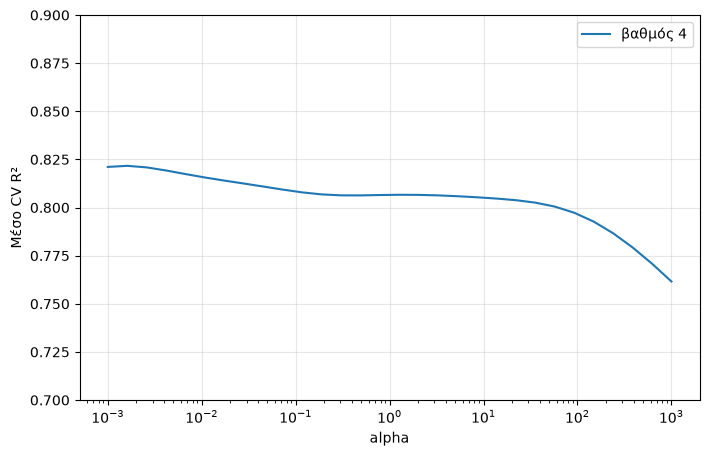

In [92]:
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
alphas = np.logspace(-3, 3, 30)   # 30 τιμες από 10^-3 έως 10^3

# Ελεγχος για καθε βαθμο
for n in [1, 2, 3, 4]:
    pipe = Pipeline([
        ('poly', PolynomialFeatures(degree=n, include_bias=False)),
        ('scaler', StandardScaler()),
        ('ridge', Ridge())
    ])
    grid = GridSearchCV(pipe, {'ridge__alpha': alphas}, cv=5)
    grid.fit(x_train_multi_lre, y_train_multi_lre)

    print(f'Βαθμός {n}: best alpha = {grid.best_params_['ridge__alpha']},')
    print(f'CV R² = {grid.best_score_}')

# Γραφημα τυπου logx
plt.figure(figsize=(8, 5))
plt.semilogx(alphas, grid.cv_results_['mean_test_score'], label=f'βαθμός {n}')
plt.xlabel('alpha')
plt.ylabel('Μέσο CV R²')
plt.ylim(0.7, 0.9)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Σχεδον copy-paste κινουμαστε για ολες τις υπολοιπες μεταβλητες

Βαθμός 1: best alpha = 3.2903445623126677,
CV R² = 0.8754834264663078
Βαθμός 2: best alpha = 0.11721022975334805,
CV R² = 0.8864811223372451
Βαθμός 3: best alpha = 0.11721022975334805,
CV R² = 0.8932277746613847
Βαθμός 4: best alpha = 0.7880462815669912,
CV R² = 0.8954642779221895


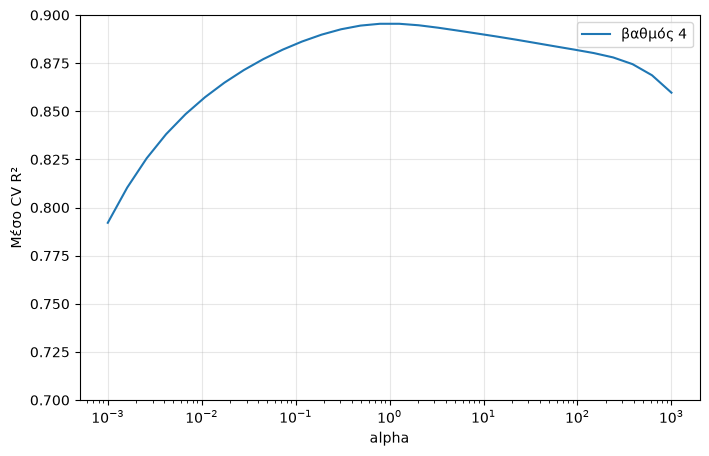

In [93]:
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
alphas = np.logspace(-3, 3, 30)   # 30 τιμες από 10^-3 έως 10^3

# Ελεγχος για καθε βαθμο
for n in [1, 2, 3, 4]:
    pipe = Pipeline([
        ('poly', PolynomialFeatures(degree=n, include_bias=False)),
        ('scaler', StandardScaler()),
        ('ridge', Ridge())
    ])
    grid = GridSearchCV(pipe, {'ridge__alpha': alphas}, cv=5)
    grid.fit(x_train_multi1_lre, y_train_multi1_lre)

    print(f'Βαθμός {n}: best alpha = {grid.best_params_['ridge__alpha']},')
    print(f'CV R² = {grid.best_score_}')

# Γραφημα τυπου logx
plt.figure(figsize=(8, 5))
plt.semilogx(alphas, grid.cv_results_['mean_test_score'], label=f'βαθμός {n}')
plt.xlabel('alpha')
plt.ylabel('Μέσο CV R²')
plt.ylim(0.7, 0.9)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Το Ridge βαθμού 4 έχει το καλύτερο CV R², με μικρή διαφορά. Θα επιβεβαιώσουμε στο test set αν η βελτίωση είναι πραγματική.

In [94]:
# Παραμετροι dictionary 120 total
param_grid = {
    'poly__degree': [1, 2, 3, 4],
    'ridge__alpha': alphas
}

# Pipe
pipe = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False)),
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])

# Εκπαιδευση
grid = GridSearchCV(pipe, param_grid, cv=5, scoring='r2')
grid.fit(x_train_multi1_lre, y_train_multi1_lre)

# Εκτυπωση
print(grid.best_params_, grid.best_score_)
best_model = grid.best_estimator_

{'poly__degree': 4, 'ridge__alpha': np.float64(0.7880462815669912)} 0.8954642779221895


Πως συμπεριφερεται το μοντελο μας στο test set

In [95]:
ridge_test = best_model.predict(x_test_multi1_lre)

# Υπολογισμος R²
ridge_r2_test = best_model.score(x_test_multi1_lre, y_test_multi1_lre)

# Υπολογισμος MSE
ridge_mse_test = mean_squared_error(y_test_multi1_lre, ridge_test)

# Εκτυπωση
print('Ridge CV R²:', grid.best_score_)
print('Ridge Test R²:', ridge_r2_test)
print('Ridge Test MSE:', ridge_mse_test)

Ridge CV R²: 0.8954642779221895
Ridge Test R²: 0.9326797081177887
Ridge Test MSE: 0.9266173436416066


Για την ολοκληρωση του project αναμενεται η δημιουργια επιπλεον γραφηματων συγκρισης των μεθοδων, εξαγωγη συμπερασματων και καλυτερη συνταξη και μορφοποιηση κειμενου, η οποια θα γινει με τη χρηση τεχνιτης νοημοσυνης.
Οι μεχρι τωρα παρατηρησεις ειναι προσωπικες